# Fig. 2: PlaSim ensemble for the modern continental configuration

In [1]:
from helpers import *
from matplotlib.colors import ListedColormap, Normalize, TwoSlopeNorm

data = load_grid("default", "0Ma")
gsols = np.array(sorted(data.keys()))

print(f"{sum(len(data[g]['co2s']) for g in gsols)} runs at {len(gsols)} solar constants")

1011 runs at 23 solar constants


In [2]:
# every run, in order of solar constant
gsol_all = np.concatenate([np.full(len(data[g]["co2s"]), g) for g in gsols])
co2_all = np.concatenate([data[g]["co2s"] for g in gsols])
albedo_all = np.concatenate([data[g]["albedo"] for g in gsols])
temp_all = np.concatenate([data[g]["temp"] for g in gsols])
wsum_all = np.concatenate([data[g]["wsum"] for g in gsols])

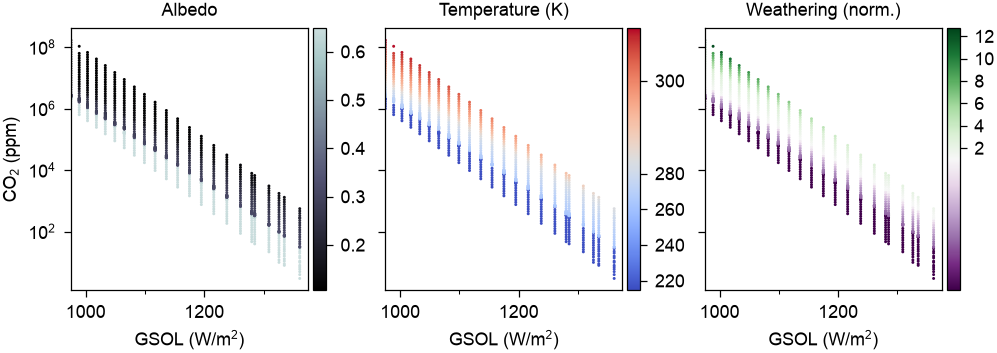

In [3]:
fig, (ax_a, ax_t, ax_w) = plt.subplots(1, 3, figsize=(FULL_WIDTH, ROW_HEIGHT), sharey=True, layout="constrained")
fig.get_layout_engine().set(wspace=0.02)
s = 2

# albedo
# bone without white, so the brightest points show
albedo_cmap = ListedColormap(plt.cm.bone(np.linspace(0, 0.85, 256)))
sc = ax_a.scatter(gsol_all, co2_all, c=albedo_all, cmap=albedo_cmap, norm=Normalize(vmin=np.nanmin(albedo_all), vmax=np.nanmax(albedo_all)),
                  s=s, linewidth=0)
ax_a.set_title("Albedo")
fig.colorbar(sc, ax=ax_a, pad=0.02)

# temperature
t_norm = TwoSlopeNorm(vcenter=288, vmin=np.nanmin(temp_all), vmax=np.nanmax(temp_all))
sc = ax_t.scatter(gsol_all, co2_all, c=temp_all, cmap="coolwarm",
                  norm=t_norm, s=s, linewidth=0)
ax_t.set_title("Temperature (K)")
fig.colorbar(sc, ax=ax_t, pad=0.02)

# weathering
w_norm = TwoSlopeNorm(vcenter=1, vmin=np.nanmin(wsum_all), vmax=np.nanmax(wsum_all))
sc = ax_w.scatter(gsol_all, co2_all, c=wsum_all, cmap="PRGn",
                  norm=w_norm, s=s, linewidth=0)
ax_w.set_title("Weathering (norm.)")
fig.colorbar(sc, ax=ax_w, pad=0.02)

for ax in (ax_a, ax_t, ax_w):
    ax.set_xlabel("GSOL (W/m$^2$)")
    ax.set_xlim(975, 1375)
    ax.set_xticks([1000, 1200])
    ax.set_xticks([1100, 1300], minor=True)
    ax.set_yscale("log")
ax_a.set_ylabel("CO$_2$ (ppm)")

plt.savefig("figs/grid_0Ma.pdf", bbox_inches="tight")
plt.show()